# 03 Explorative Datenanalyse (EDA)

**Ziel:** Die EDA beantwortet die Frage, wann, wo und unter welchen Umständen Unfälle schwer verlaufen – und wie stark ein Umstand das Risiko erhöht. Daraus werden später die Maßnahmen abgeleitet.

**Vorgehen:**

1. **Fehlende Werte prüfen (3.1):** Merkmale mit mehr als 20 % fehlenden Werten sind nicht belastbar und werden nicht verwendet. Ebenso entfallen Angaben zu Unfallfolgen und die widersprüchlich erfasste Anzahl der Fahrzeuge.

2. **Merkmale einzeln untersuchen (3.2):** Für jedes Merkmal wird der Anteil schwerer Unfälle je Gruppe mit dem Durchschnitt (16,6 %) verglichen. Ein Merkmal wird beibehalten, wenn mindestens eine Gruppe (≥ 50 Unfälle) deutlich darüber liegt; sonst wird es verworfen.

3. **Merkmale kombinieren (3.3):** Nur die beibehaltenen Merkmale werden kombiniert, da sich Risiken verstärken können (z. B. nachts + freie Strecke + Wohngebiet). So entstehen konkrete Situationen, die beschreiben, wann, wo und bei welchem Unfalltyp Maßnahmen ansetzen sollten.

**Analyseebene:** Merkmale, die den Unfall als Ganzes beschreiben (Zeit, Ort, Licht, Wetter, Anzahl Fahrzeuge, Unfalltyp), werden auf Unfallebene (`df_unfall`, 9.517 Unfälle) ausgewertet. Merkmale, die sich je Fahrzeug unterscheiden (Fahreralter, Fahrerfahrung, Fahrzeugtyp, Ursache), werden auf Fahrzeugebene (`df_clean`, 12.316 Zeilen) ausgewertet. Vergleichsmaßstab ist jeweils der Durchschnitt der Ebene.

**Kernzeichen Überschuss:** Um Situationen zu priorisieren, wird der Überschuss berechnet:

> Überschuss = beobachtete schwere Unfälle − erwartete schwere Unfälle (Anzahl Unfälle × 16,6 %)

Er zeigt, wie viele schwere Unfälle eine Situation mehr verursacht als der Durchschnitt. Da er Häufigkeit und Gefährlichkeit verbindet, gibt er an, wo eine Maßnahme die meisten schweren Unfälle vermeiden kann.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_clean  = pd.read_parquet('../../data/df_features.parquet')
df_unfall = pd.read_parquet('../../data/df_unfall.parquet')

text_cols = df_clean.select_dtypes(exclude='number').columns.drop('Time')

In [66]:
def schwere_je_merkmal(df, col, min_n=50):
    """Anteil schwerer Unfälle je Ausprägung und Überschuss gegenüber dem Durchschnitt."""
    basis = df["schwer"].mean()
    g = df.groupby(col, observed=True)["schwer"].agg(n="size", schwer="sum", anteil="mean")
    g = g[g["n"] >= min_n]
    g["ueberschuss"] = (g["schwer"] - g["n"] * basis).round(0)
    g["anteil"] = (g["anteil"] * 100).round(1)
    return g.sort_values("ueberschuss", ascending=False)

def plot_anteil(df, col, titel, min_n=50):
    basis = df["schwer"].mean() * 100
    g = schwere_je_merkmal(df, col, min_n).sort_values("anteil")
    fig, ax = plt.subplots(figsize=(7, 0.4 * len(g) + 1.2))
    farben = ["#c0392b" if a > basis else "#9bb8d9" for a in g["anteil"]]
    ax.barh(g.index.astype(str), g["anteil"], color=farben)
    ax.axvline(basis, ls="--", color="black", lw=1, label=f"Durchschnitt {basis:.1f} %".replace(".", ","))
    for i, (a, n) in enumerate(zip(g["anteil"], g["n"])):
        ax.text(a + 0.3, i, f"{a:.1f} % (n={n:.0f})".replace(".", ","), va="center", fontsize=8)
    ax.set_xlabel("Anteil schwerer Unfälle (%)"); ax.set_title(titel, loc="left", fontweight="bold")
    ax.legend(loc="lower right"); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()


### Verteilung der Unfallschwere

In [67]:
# Fahrzeugebene (Zeilen) und Unfallebene – 2 Gruppen: leicht / schwer (inkl. tödlich)
for name, d in [("Fahrzeugebene", df_clean), ("Unfallebene", df_unfall)]:
    print(f"--- {name} ---")
    print(d["schwer"].map({0: "leicht", 1: "schwer (inkl. tödlich)"}).value_counts().rename_axis(None).to_string())
    print("Anteil schwer:", round(d["schwer"].mean() * 100, 1), "%\n")

--- Fahrzeugebene ---
leicht                    10415
schwer (inkl. tödlich)     1901
Anteil schwer: 15.4 %

--- Unfallebene ---
leicht                    7940
schwer (inkl. tödlich)    1577
Anteil schwer: 16.6 %



Der Anteil schwerer Unfälle beträgt 16,6 % je Unfall bzw. 15,4 % je Fahrzeug.

### 3.1 Fehlende Werte

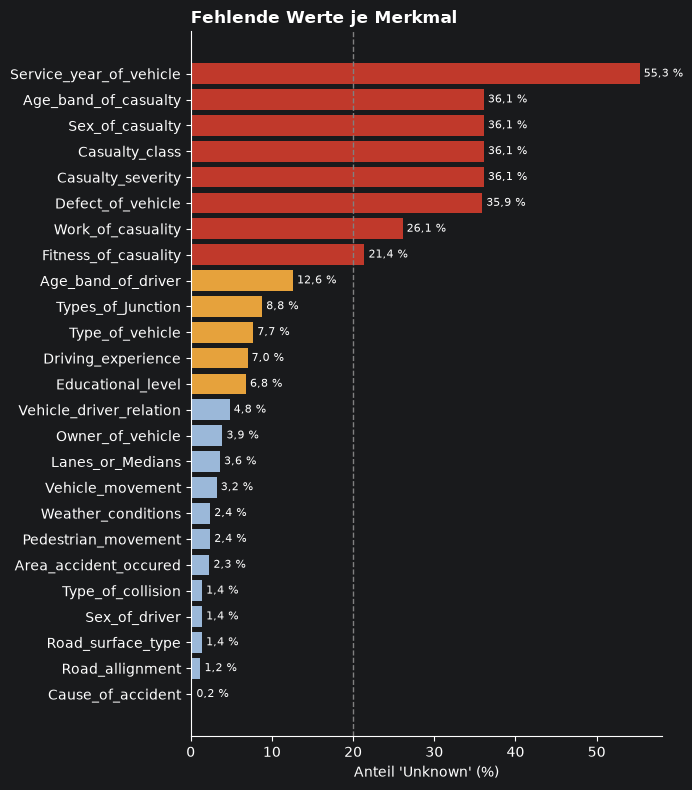

In [68]:
fehlend = (df_clean[text_cols] == "Unknown").mean().mul(100).round(1).sort_values()
fehlend = fehlend[fehlend > 0]

fig, ax = plt.subplots(figsize=(7, 8))
farben = ["#c0392b" if v > 20 else "#e6a23c" if v > 5 else "#9bb8d9" for v in fehlend]
ax.barh(fehlend.index, fehlend, color=farben)
for i, v in enumerate(fehlend):
    ax.text(v + 0.5, i, f"{v:.1f} %".replace(".", ","), va="center", fontsize=8)
ax.axvline(20, ls="--", color="grey", lw=1)
ax.set_xlabel("Anteil 'Unknown' (%)")
ax.set_title("Fehlende Werte je Merkmal", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

Die für die Maßnahmenableitung zentralen Merkmale – Unfallursache (0,2 %), Gebiet (2,3 %), Wetter, Licht und Straßenzustand (< 3 %) – sind nahezu vollständig und damit belastbar.

Stark lückenhaft sind das Fahrzeugalter (55,3 %), Fahrzeugmängel (35,9 %) sowie die vier Angaben zu Verunglückten (je 36,1 %, gemeinsam fehlend). Diese Merkmale werden nicht verwendet; ein Einfluss des Fahrzeugalters kann daher nicht geprüft werden (→ Limitationen).

### 3.2 Anteil schwerer Unfälle je Merkmal

| Gruppe | Merkmal | Verwendung | Begründung |
|---|---|---|---|
| **Zeit** | Time (→ Stunde, Tageszeit) | ✅ | Zeitliche Planung von Kontrollen und Beleuchtung |
| | Day_of_week (→ Wochenende) | ✅ | Prüfung der Hypothese "Wochenende" |
| **Ort & Straße** | Area_accident_occured | ✅ | Räumliche Zuordnung von Maßnahmen |
| | Types_of_Junction | ✅ | Hinweis auf Knotenpunktgestaltung |
| | Road_allignment | ✅ | Hinweis auf Kurven, Gefälle |
| | Lanes_or_Medians | ✅ | Hinweis auf fehlende Mitteltrennung |
| | Road_surface_type | ❌ | Geringe Aussagekraft für Maßnahmen |
| **Umwelt** | Light_conditions | ✅ | Hinweis auf fehlende Beleuchtung |
| | Weather_conditions | ✅ | Prüfung der Hypothese „Wetter"|
| | Road_surface_conditions | ✅ | Prüfung der Hypothese „Nässe" |
| **Fahrer** | Age_band_of_driver | ✅ | Zielgruppe für Kontrollen (z. B. < 18) |
| | Driving_experience | ✅ | Prüfung der Hypothese "Fahranfänger"|
| | Sex_of_driver, Educational_level, Vehicle_driver_relation | ❌ | Keine Maßnahme ableitbar |
| **Fahrzeug** | Type_of_vehicle (→ Fahrzeuggruppe) | ✅ | Fahrzeugspezifische Maßnahmen |
| | Owner_of_vehicle | ❌ | Keine Maßnahme ableitbar |
| | Service_year_of_vehicle, Defect_of_vehicle | ❌ | 36–55 % fehlende Werte |
| **Unfallhergang** | Cause_of_accident | ✅ | Zentrale Ursache, Grundlage der Maßnahmenwahl |
| | Type_of_collision | ✅ | Unfalltyp (Fußgänger, Objekt am Straßenrand …) |
| | Number_of_vehicles_involved | ❌ | Widersprüchlich kodiert (viele „Ein-Fahrzeug-Unfälle" als Kollision zweier Fahrzeuge erfasst); nur für die Unfall-ID genutzt |
| | Pedestrian_movement | ✅ | Hinweis auf Querungssituationen |
| | Vehicle_movement | ❌ | Weitgehend durch Cause_of_accident abgedeckt |
| **Unfallfolgen** | **Accident_severity (→ schwer)** | 🎯 | **Zielvariable** |
| | Number_of_casualties, Casualty_* , Work/Fitness_of_casuality | ❌ | Unfallfolgen, keine Ursachen; 21–36 % fehlend |

**Auswahlkriterien:**
1.  Das Merkmal beschreibt Umstände vor oder während des Unfalls,
2. es lässt sich einer Maßnahme zuordnen oder dient der Prüfung einer verbreiteten Annahme,
3.  der Anteil fehlender Werte ist vertretbar.

In [69]:
unfall_merkmale = ["Tageszeit", "Area_accident_occured", "Light_conditions",
                   "Type_of_collision", "Types_of_Junction", "Road_allignment", "Lanes_or_Medians",
                   "Wochenende", "Weather_conditions", "Road_surface_conditions"]
fahrzeug_merkmale = ["Cause_of_accident", "Age_band_of_driver", "Driving_experience",
                     "Fahrzeuggruppe", "Pedestrian_movement"]

for col in unfall_merkmale:
    print(f"\n=== {col} (je Unfall) ===")
    display(schwere_je_merkmal(df_unfall, col).head(6))
for col in fahrzeug_merkmale:
    print(f"\n=== {col} (je Fahrzeug) ===")
    display(schwere_je_merkmal(df_clean, col).head(6))


=== Tageszeit (je Unfall) ===


,n,schwer,anteil,ueberschuss
Tageszeit,,,,
Abend (20-23),1278,254,19.9,42.0
Nacht (0-5),537,112,20.9,23.0
Morgen (6-9),1641,258,15.7,-14.0
Tag (10-15),3106,489,15.7,-26.0
Abend-Rush (16-19),2955,464,15.7,-26.0



=== Area_accident_occured (je Unfall) ===


,n,schwer,anteil,ueberschuss
Area_accident_occured,,,,
Residential areas,1669,310,18.6,33.0
Other,2654,447,16.8,7.0
Office areas,2446,411,16.8,6.0
Outside rural areas,156,29,18.6,3.0
Unknown,269,46,17.1,1.0
Market areas,63,10,15.9,-0.0



=== Light_conditions (je Unfall) ===


,n,schwer,anteil,ueberschuss
Light_conditions,,,,
Darkness - no lighting,157,41,26.1,15.0
Darkness - lights lit,2599,436,16.8,5.0
Daylight,6730,1094,16.3,-21.0


... (20 outputs left out)


=== Fahrzeuggruppe (je Fahrzeug) ===


,n,schwer,anteil,ueberschuss
Fahrzeuggruppe,,,,
Lkw/Pick-up,3921,630,16.1,25.0
Pkw,4157,661,15.9,19.0
Bus,1647,256,15.5,2.0
Zweirad/Dreirad,227,36,15.9,1.0
Sonstige/Unknown,2364,318,13.5,-47.0



=== Pedestrian_movement (je Fahrzeug) ===


,n,schwer,anteil,ueberschuss
Pedestrian_movement,,,,
Crossing from driver's nearside,140,29,20.7,7.0
Crossing from nearside - masked by parked or statioNot a Pedestrianry vehicle,337,58,17.2,6.0
Unknown,293,47,16.0,2.0
Crossing from offside - masked by parked or statioNot a Pedestrianry vehicle,72,11,15.3,-0.0
Not a Pedestrian,11390,1748,15.3,-10.0


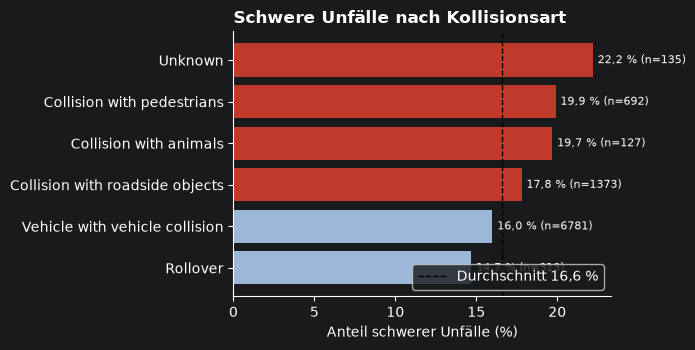

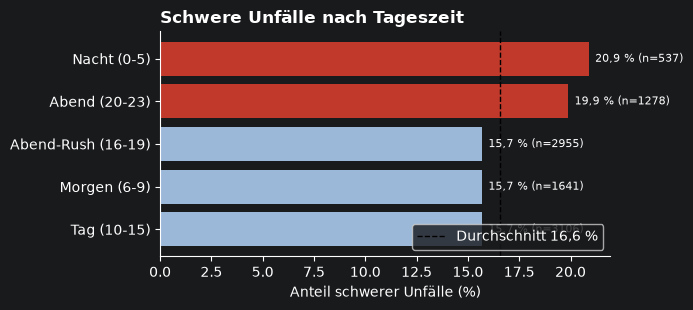

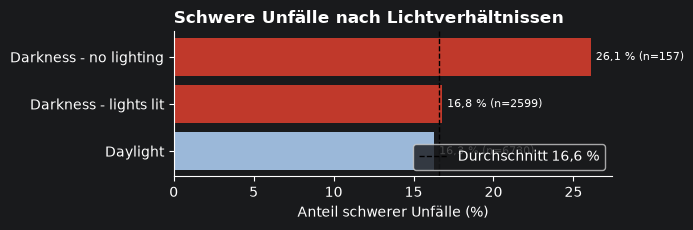

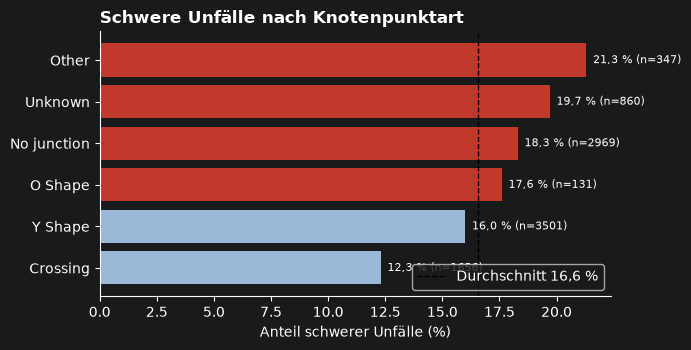

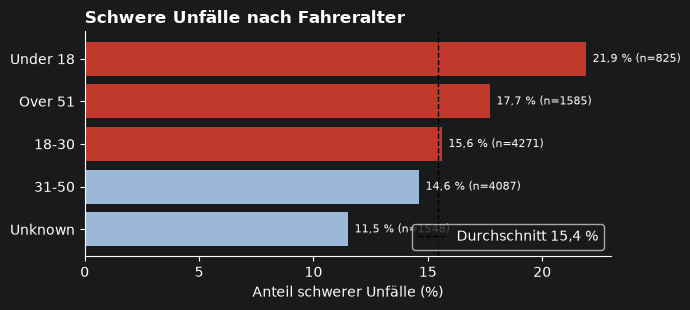

In [70]:
plot_anteil(df_unfall, "Type_of_collision", "Schwere Unfälle nach Kollisionsart")
plot_anteil(df_unfall, "Tageszeit", "Schwere Unfälle nach Tageszeit")
plot_anteil(df_unfall, "Light_conditions", "Schwere Unfälle nach Lichtverhältnissen")
plot_anteil(df_unfall, "Types_of_Junction", "Schwere Unfälle nach Knotenpunktart")
plot_anteil(df_clean, "Age_band_of_driver", "Schwere Unfälle nach Fahreralter")

**Ergebnis der Einzelanalyse: beibehaltene Merkmale**

| Merkmal | Auffällige Gruppe(n) | Anteil schwer | Überschuss | Ebene | Weiterverwendung |
|---|---|---|---|---|---|
| Tageszeit | Abend (20–23 Uhr), Nacht (0–5 Uhr) | 19,9 % / 20,9 % | +42 / +23 | Unfall | Kombination|
| Types_of_Junction | Freie Strecke („No junction") | 18,4 % | +53 | Unfall | Kombination|
| Area_accident_occured | Wohngebiet | 18,6 % | +33 | Unfall | Kombination|
| Type_of_collision | Fußgänger, Objekt am Straßenrand | 20,3 % / 18,2 % | +26 / +23 | Unfall | Kombination|
| Light_conditions | Dunkelheit ohne Beleuchtung | 26,1 % | +15 | Unfall | Kombination |**
| Age_band_of_driver | unter 18, über 51 Jahre | 21,9 % / 17,7 % | +54 / +36 | Fahrzeug | eigene Regel |
| Cause_of_accident | Überholen, Fahren auf der Gegenspur | 18,4 % / 20,1 % | je +13 | Fahrzeug | eigene Regel |

**Verworfene Merkmale (kein deutlicher Unterschied zum Durchschnitt)**

| Merkmal | Ergebnis |
|---|---|
| Road_allignment, Lanes_or_Medians | alle Gruppen nahe am Durchschnitt |
| Wochenende | 17,0 % vs. 16,4 % – kaum Unterschied|
| Weather_conditions, Road_surface_conditions | kein erhöhter Anteil, Regen sogar geringer|
| Driving_experience | alle Gruppen 14–16 %|
| Fahrzeuggruppe | alle Gruppen 15–16 % |
| Pedestrian_movement | auffällige Gruppe zu klein; bereits durch „Fußgänger" abgedeckt |

### 3.3 Kombinationen von Merkmalen
Kombiniert werden die Merkmale mit dem größten Überschuss aus 4.3. Sie entsprechen den Fragen, die jede Maßnahme beantworten muss: Welcher Unfalltyp? Wann? Wo? Mindestgröße je Gruppe: n ≥ 40.

In [71]:
def kombination(df, cols, min_n=40, top=8):
    return schwere_je_merkmal(df, cols, min_n).head(top)

display(kombination(df_unfall, ["Area_accident_occured", "Tageszeit"]))
display(kombination(df_unfall, ["Types_of_Junction", "Tageszeit"]))
display(kombination(df_unfall, ["Type_of_collision", "Tageszeit"]))
display(kombination(df_unfall, ["Light_conditions", "Type_of_collision"], top=5))

n  schwer  anteil  ueberschuss
Area_accident_occured Tageszeit                                           
Residential areas     Abend (20-23)       242      56    23.1         16.0
Office areas          Abend (20-23)       343      72    21.0         15.0
Other                 Abend-Rush (16-19)  835     148    17.7         10.0
Residential areas     Nacht (0-5)          98      25    25.5          9.0
Outside rural areas   Tag (10-15)          56      15    26.8          6.0
Residential areas     Morgen (6-9)        273      51    18.7          6.0
                      Abend-Rush (16-19)  519      91    17.5          5.0
Office areas          Nacht (0-5)         134      27    20.1          5.0

n  schwer  anteil  ueberschuss
Types_of_Junction Tageszeit                                           
No junction       Abend (20-23)       386      94    24.4         30.0
                  Nacht (0-5)         198      56    28.3         23.0
                  Morgen (6-9)        517      98    19.0         12.0
Other             Tag (10-15)         144      35    24.3         11.0
Unknown           Abend-Rush (16-19)  264      54    20.5         10.0
                  Abend (20-23)       117      29    24.8         10.0
Y Shape           Abend (20-23)       433      82    18.9         10.0
No junction       Tag (10-15)         945     163    17.2          6.0

n  schwer  anteil  \
Type_of_collision               Tageszeit                            
Vehicle with vehicle collision  Abend (20-23)  894     173    19.4   
                                Nacht (0-5)    386      83    21.5   
Collision with pedestrians      Abend (20-23)   95      32    33.7   
Collision with roadside objects Tag (10-15)    460      89    19.3   
                                Morgen (6-9)   228      42    18.4   
Unknown                         Tag (10-15)     51      11    21.6   
Collision with pedestrians      Morgen (6-9)   113      21    18.6   
Collision with animals          Tag (10-15)     53      11    20.8   

                                               ueberschuss  
Type_of_collision               Tageszeit                   
Vehicle with vehicle collision  Abend (20-23)         25.0  
                                Nacht (0-5)           19.0  
Collision with pedestrians      Abend (20-23)         16.0  
Collision with roadside objects Tag (10-15)           13.0  
                                Morgen (6-9)           4.0  
Unknown                         Tag (10-15)            3.0  
Collision with pedestrians      Morgen (6-9)           2.0  
Collision with animals          Tag (10-15)            2.0

,,n,schwer,anteil,ueberschuss
Light_conditions,Type_of_collision,,,,
Daylight,Collision with roadside objects,962,175,18.2,16.0
Darkness - no lighting,Vehicle with vehicle collision,116,29,25.0,10.0
Daylight,Collision with pedestrians,473,88,18.6,10.0
Darkness - lights lit,Collision with pedestrians,205,43,21.0,9.0
Daylight,Unknown,104,23,22.1,6.0


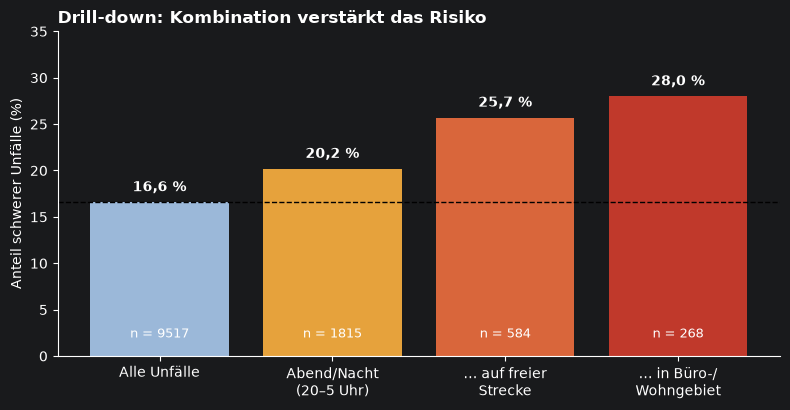

In [72]:
d = df_unfall
basis = d["schwer"].mean()
an = d["Abend_Nacht"] == 1
frei = d["Freie_Strecke"] == 1
bw = d["Area_accident_occured"].isin(["Office areas", "Residential areas"])
stufen = [("Alle Unfälle", d), ("Abend/Nacht\n(20–5 Uhr)", d[an]),
          ("… auf freier\nStrecke", d[an & frei]), ("… in Büro-/\nWohngebiet", d[an & frei & bw])]
vals = [s["schwer"].mean() * 100 for _, s in stufen]
ns = [len(s) for _, s in stufen]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar([l for l, _ in stufen], vals, color=["#9bb8d9", "#e6a23c", "#d9663b", "#c0392b"])
for i, (v, n) in enumerate(zip(vals, ns)):
    ax.text(i, v + 1.2, f"{v:.1f} %".replace(".", ","), ha="center", fontweight="bold")
    ax.text(i, 2, f"n = {n}", ha="center", color="white", fontsize=9)
ax.axhline(basis * 100, ls="--", color="black", lw=1)
ax.set_ylabel("Anteil schwerer Unfälle (%)"); ax.set_ylim(0, 35)
ax.set_title("Drill-down: Kombination verstärkt das Risiko", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

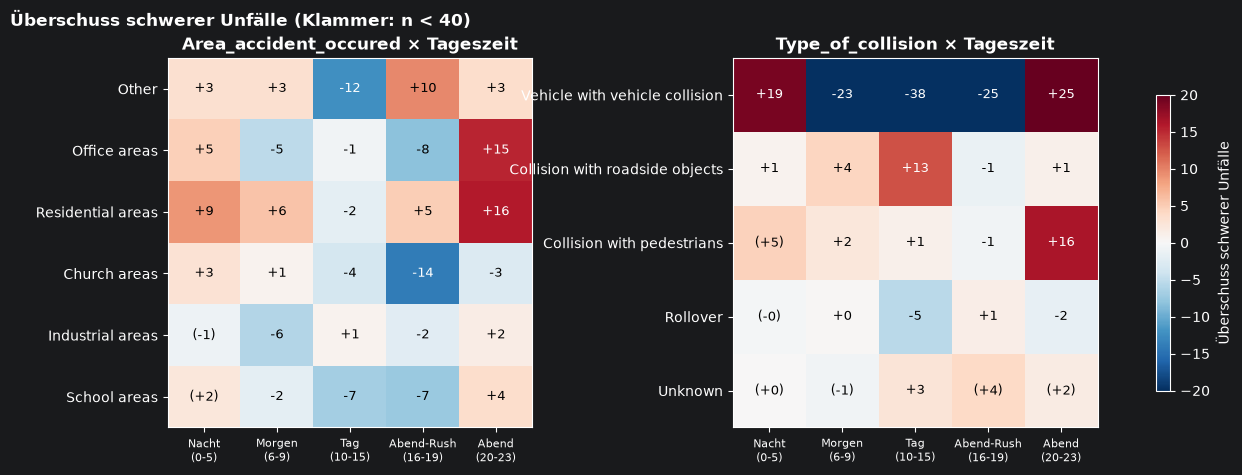

In [73]:
tz = list(d["Tageszeit"].cat.categories)

def heatmap(ax, zeilen_col, zeilen, titel):
    g = (d[d[zeilen_col].isin(zeilen)].groupby([zeilen_col, "Tageszeit"], observed=False)["schwer"]
         .agg(["size", "sum"]))
    ue = (g["sum"] - g["size"] * basis).unstack().reindex(zeilen)
    n = g["size"].unstack().reindex(zeilen)
    im = ax.imshow(ue.values, cmap="RdBu_r", vmin=-20, vmax=20, aspect="auto")
    for i in range(ue.shape[0]):
        for j in range(ue.shape[1]):
            v, nn = ue.values[i, j], n.values[i, j]
            txt = f"{v:+.0f}" if nn >= 40 else f"({v:+.0f})"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9, color="white" if abs(v) > 12 else "black")
    ax.set_xticks(range(len(tz))); ax.set_xticklabels([t.replace(" (", "\n(") for t in tz], fontsize=8)
    ax.set_yticks(range(len(zeilen))); ax.set_yticklabels(zeilen); ax.set_title(titel, fontweight="bold")
    return im

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"wspace": 0.55})
heatmap(axs[0], "Area_accident_occured", list(d["Area_accident_occured"].value_counts().index[:6]), "Area_accident_occured × Tageszeit")
im = heatmap(axs[1], "Type_of_collision", list(d["Type_of_collision"].value_counts().index[:5]), "Type_of_collision × Tageszeit")
fig.colorbar(im, ax=axs, label="Überschuss schwerer Unfälle", shrink=0.8)
fig.suptitle("Überschuss schwerer Unfälle (Klammer: n < 40)", x=0.02, ha="left", fontweight="bold")
plt.show()

- **Kombinationen verstärken das Risiko:** Abend/Nacht (20–5 Uhr) 20,2 % schwer, zusätzlich auf freier Strecke 25,6 %, zusätzlich in Büro- oder Wohngebieten **28,0 %** (n = 268).
- **Wann und wo:** Die größten Überschüsse liegen in Wohn- und Bürogebieten am Abend (23,1 % bzw. 21,0 %; +16 / +15) sowie auf freier Strecke abends und nachts (24,2 % bzw. 28,3 %; +30 / +23).
- **Tageszeit wirkt über alle Unfallarten:** Auch Kollisionen zwischen Fahrzeugen sind abends und nachts überdurchschnittlich schwer (+23 / +17), tagsüber dagegen deutlich unterdurchschnittlich – ein Hinweis auf höhere Geschwindigkeiten bei geringem Verkehr.
- **Art des Unfalls:** Fußgängerunfälle am Abend und in der Nacht sind zu 32–33 % schwer; Kollisionen mit Objekten am Straßenrand vor allem tagsüber (19,9 %, +15).
- **Dunkelheit:** Fußgängerkollisionen bei Dunkelheit trotz Beleuchtung 22,8 %, Kollisionen bei Dunkelheit ohne Beleuchtung 25,2 %.
- **Einschränkung:** Dreifachkombinationen beruhen auf kleineren Gruppen und sind als Tendenz zu interpretieren.

### 3.4 Nicht bestätigte Hypothesen
Im Maßnahmenraum wurden auch verbreitete Annahmen als Hypothesen formuliert. Die folgenden Hypothesen werden durch die Daten nicht bestätigt:

| Nr. | Hypothese | Mögliche Maßnahme | Ergebnis | Bewertung |
|---|---|---|---|---|
| **H9** | Unfälle von Fahrern mit wenig Fahrerfahrung sind häufiger schwer. | Schulungen für Fahranfänger | Alle Erfahrungsgruppen liegen bei 14–16 % (unter 1 Jahr: 15,9 %; Durchschnitt je Fahrzeug: 15,4 %). | ❌ nicht bestätigt |
| **H10a** | Unfälle bei Regen sind häufiger schwer. | Warnhinweise, wetterabhängige Tempolimits | Bei Regen 14,4 %, bei normalem Wetter 17,3 % – Regen geht sogar mit *weniger* schweren Unfällen einher. | ❌ nicht bestätigt |
| **H10b** | Unfälle auf nasser Fahrbahn sind häufiger schwer. | Griffige Fahrbahnbeläge | Nass 16,0 %, trocken 16,8 % – kein relevanter Unterschied. | ❌ nicht bestätigt |
| **H11** | Unfälle am Wochenende sind häufiger schwer. | Verstärkte Kontrollen am Wochenende | Wochenende 17,0 %, Werktag 16,4 % – kein deutlicher Unterschied. | ❌ nicht bestätigt |

**Mögliche Erklärung:** Bei Regen und Nässe wird vermutlich vorsichtiger und langsamer gefahren, was die Schwere der Unfälle verringert.

**Nicht prüfbar** sind zwei weitere verbreitete Annahmen:
- **Alkohol** erhöht die Unfallschwere – nur 27 Fälle mit Alkohol als Ursache erfasst, vermutlich stark untererfasst.
- **Ältere Fahrzeuge** sind an schwereren Unfällen beteiligt – 55 % fehlende Werte beim Fahrzeugalter.

**Folgerung:** Maßnahmen gegen Witterungseinflüsse, allgemeine Fahranfängerschulungen und Wochenendkontrollen werden auf Basis dieser Daten **nicht priorisiert**. Das Budget wird auf die bestätigten Situationen konzentriert (Kapitel 6).

In [74]:
for df_, col in [(df_unfall, "Weather_conditions"), (df_unfall, "Road_surface_conditions"),
                (df_unfall, "Wochenende"), (df_clean, "Driving_experience"),
                (df_clean, "Sex_of_driver"), (df_clean, "Educational_level")]:
    print(f"\n=== {col} ===")
    display(schwere_je_merkmal(df_, col))

print("Alkohol/Drogen als Ursache:")
print(df_clean[df_clean["Cause_of_accident"].str.contains("Drunk|drug", case=False)]
      .groupby("Cause_of_accident")["schwer"].agg(["size", "mean"]))


=== Weather_conditions ===


,n,schwer,anteil,ueberschuss
Weather_conditions,,,,
Normal,7690,1329,17.3,55.0
Windy,84,15,17.9,1.0
Unknown,239,41,17.2,1.0
Cloudy,106,7,6.6,-11.0
Other,243,23,9.5,-17.0
Raining,1072,154,14.4,-24.0



=== Road_surface_conditions ===


,n,schwer,anteil,ueberschuss
Road_surface_conditions,,,,
Dry,7165,1202,16.8,15.0
Wet or damp,2303,371,16.1,-11.0



=== Wochenende ===


,n,schwer,anteil,ueberschuss
Wochenende,,,,
1,2432,414,17.0,11.0
0,7085,1163,16.4,-11.0


... (3 outputs left out)

,n,schwer,anteil,ueberschuss
Sex_of_driver,,,,
Male,11437,1773,15.5,8.0
Female,701,109,15.5,1.0
Unknown,178,19,10.7,-8.0



=== Educational_level ===


,n,schwer,anteil,ueberschuss
Educational_level,,,,
Elementary school,2163,338,15.6,4.0
Junior high school,7619,1180,15.5,4.0
Unknown,841,133,15.8,3.0
Above high school,362,58,16.0,2.0
Writing & reading,176,25,14.2,-2.0
High school,1110,161,14.5,-10.0


Alkohol/Drogen als Ursache:
                                      size      mean
Cause_of_accident                                   
Driving under the influence of drugs   340  0.150000
Drunk driving                           27  0.111111


### 3.5 Zusammenfassung der EDA
Die Grafik fasst die Ergebnisse aus 3.1–3.4 zusammen. Der Faktor zeigt, wie viel häufiger ein Unfall unter diesem Umstand schwer ist als im Durchschnitt der jeweiligen Ebene.

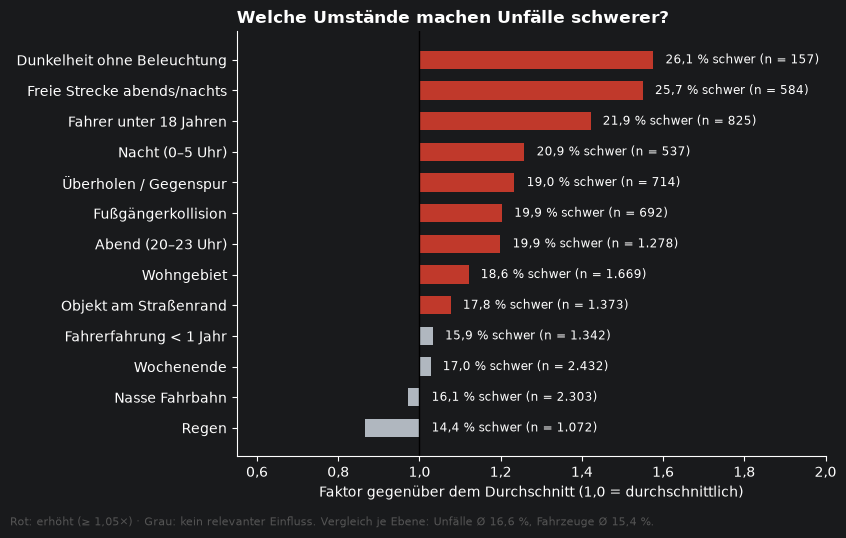

In [75]:
# Zusammenfassung: Risikofaktor = Anteil schwer / Durchschnitt der jeweiligen Ebene
bu, bf = df_unfall["schwer"].mean(), df_clean["schwer"].mean()
faktoren = [  # (Bezeichnung, Datenebene, Bedingung)
    ("Freie Strecke abends/nachts",    df_unfall, (df_unfall["Freie_Strecke"] == 1) & (df_unfall["Abend_Nacht"] == 1)),
    ("Objekt am Straßenrand",          df_unfall, df_unfall["Type_of_collision"] == "Collision with roadside objects"),
    ("Dunkelheit ohne Beleuchtung",    df_unfall, df_unfall["Light_conditions"] == "Darkness - no lighting"),
    ("Fahrer unter 18 Jahren",         df_clean,  df_clean["Age_band_of_driver"] == "Under 18"),
    ("Nacht (0–5 Uhr)",                df_unfall, df_unfall["Tageszeit"] == "Nacht (0-5)"),
    ("Fußgängerkollision",             df_unfall, df_unfall["Type_of_collision"] == "Collision with pedestrians"),
    ("Abend (20–23 Uhr)",              df_unfall, df_unfall["Tageszeit"] == "Abend (20-23)"),
    ("Überholen / Gegenspur",          df_clean,  df_clean["Cause_of_accident"].isin(["Overtaking", "Driving to the left"])),
    ("Wohngebiet",                     df_unfall, df_unfall["Area_accident_occured"] == "Residential areas"),
    ("Wochenende",                     df_unfall, df_unfall["Wochenende"] == 1),
    ("Nasse Fahrbahn",                 df_unfall, df_unfall["Road_surface_conditions"] == "Wet or damp"),
    ("Fahrerfahrung < 1 Jahr",         df_clean,  df_clean["Driving_experience"] == "Below 1yr"),
    ("Regen",                          df_unfall, df_unfall["Weather_conditions"] == "Raining"),
]
rows = []
for name, d_, m in faktoren:
    basis_ = d_["schwer"].mean()
    rows.append((name, d_.loc[m, "schwer"].mean() * 100, m.sum(), d_.loc[m, "schwer"].mean() / basis_))
zus = pd.DataFrame(rows, columns=["Faktor", "Anteil", "n", "Risiko"]).sort_values("Risiko")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
farben = ["#c0392b" if r >= 1.05 else "#b0b7bf" for r in zus["Risiko"]]
ax.barh(zus["Faktor"], zus["Risiko"] - 1, left=1, color=farben, height=0.6)
ax.axvline(1, color="black", lw=1)
for i, (r, a, n) in enumerate(zip(zus["Risiko"], zus["Anteil"], zus["n"])):
    ax.text(max(r, 1) + 0.03, i, f"{a:.1f} % schwer (n = {n:,})".replace(",", "X").replace(".", ",").replace("X", "."),
            va="center", ha="left", fontsize=8.5)
ax.set_xlim(0.55, 2.0)
ax.set_xlabel("Faktor gegenüber dem Durchschnitt (1,0 = durchschnittlich)")
ax.set_title("Welche Umstände machen Unfälle schwerer?", loc="left", fontweight="bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
fig.text(0.01, -0.02, "Rot: erhöht (≥ 1,05×) · Grau: kein relevanter Einfluss. "
        "Vergleich je Ebene: Unfälle Ø 16,6 %, Fahrzeuge Ø 15,4 %.",
        fontsize=8, color="#555")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("risikofaktoren_uebersicht.png", dpi=200, bbox_inches="tight"); plt.show()

- Dunkelheit ohne Beleuchtung und freie Strecke abends/nachts sind gut 1,5-mal so häufig schwer wie der Durchschnitt – die stärksten Einflussfaktoren.
- Fahrer unter 18 Jahren, Nacht- und Abendstunden, Überholen, Fußgängerkollisionen und Wohngebiete erhöhen das Risiko um 10–40 %.
- Wetter, Nässe, Wochenende und Fahrerfahrung haben keinen relevanten Einfluss; Regen geht sogar mit weniger schweren Unfällen einher.

Daraus ergibt sich der Fokus der Maßnahmen: Geschwindigkeit und Sichtbarkeit am Abend und in der Nacht – in Wohn- und Bürogebieten sowie auf freier Strecke.